# AI Usage by Age Group (2026)
**Question:** Which age groups use AI the most, and how does the gap between younger and older people look across countries?

**Data:** `ai_usage_by_age_2026.xlsx` (sheet `Data`), collected from Roy Morgan, Pew Research, Swissinfo, Shift, and others. See the `Sources` sheet.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams['axes.spines.left']=True

## 1. Load the data

In [2]:
df = pd.read_excel("/Users/charanreddy/Downloads/ai_usage_by_age_2026.xlsx", sheet_name="Data")
print(df.shape)
df.head(10)

(20, 10)


,ID,Country,Source,Survey period,Age group,Metric,Value (%),Value type,Source ID,Notes
0,1,Australia,Roy Morgan,Jan-Mar 2026,14-17,"Use AI tools (ChatGPT, Copilot, Gemini, etc.)",66.0,Reported,S1,"Base: Australians 14+, n=14,646"
1,2,Australia,Roy Morgan,Jan-Mar 2026,18-24,"Use AI tools (ChatGPT, Copilot, Gemini, etc.)",68.0,Reported,S1,"Base: Australians 14+, n=14,646"
2,3,Australia,Roy Morgan,Jan-Mar 2026,25-34,"Use AI tools (ChatGPT, Copilot, Gemini, etc.)",74.0,Reported,S1,Highest of all age groups
3,4,Australia,Roy Morgan,Jan-Mar 2026,35-49,"Use AI tools (ChatGPT, Copilot, Gemini, etc.)",72.0,Reported,S1,NaN
4,5,Australia,Roy Morgan,Jan-Mar 2026,50-64,"Use AI tools (ChatGPT, Copilot, Gemini, etc.)",NaN,TO FILL,S1,Not captured in my search - open the Roy Morga...
5,6,Australia,Roy Morgan,Jan-Mar 2026,65+,"Use AI tools (ChatGPT, Copilot, Gemini, etc.)",NaN,TO FILL,S1,Not captured in my search - open the Roy Morga...
6,7,Switzerland,Swissinfo,Check source,18-35,Use AI in everyday life,90.1,Reported,S2,Survey date not shown in the excerpt I saw - v...
7,8,Switzerland,Swissinfo,Check source,55+,Use AI in everyday life,52.1,Reported,S2,Survey date not shown in the excerpt I saw - v...
8,9,USA,Pew Research,Check source,18-29,"Ever use AI chatbots (ChatGPT, Gemini, Copilot)",66.0,Reported,S3,From a Pew chart page; confirm the survey year...
9,10,USA,Pew Research,Check source,30-49,"Ever use AI chatbots (ChatGPT, Gemini, Copilot)",61.0,Reported,S3,From a Pew chart page; confirm the survey year...


## 2. Inspect and clean

In [3]:
df.info()
print()
print("Missing values per column:")
print(df.isna().sum())




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             20 non-null     int64  
 1   Country        20 non-null     object 
 2   Source         20 non-null     object 
 3   Survey period  20 non-null     object 
 4   Age group      20 non-null     object 
 5   Metric         20 non-null     object 
 6   Value (%)      18 non-null     float64
 7   Value type     20 non-null     object 
 8   Source ID      20 non-null     object 
 9   Notes          19 non-null     object 
dtypes: float64(1), int64(1), object(8)
memory usage: 1.7+ KB

Missing values per column:
ID               0
Country          0
Source           0
Survey period    0
Age group        0
Metric           0
Value (%)        2
Value type       0
Source ID        0
Notes            1
dtype: int64


In [4]:

df.columns = (df.columns.str.lower()
                .str.replace(r"[()%]", "", regex=True)
                .str.strip()
                .str.replace(" ", "_"))

for col in ["country", "source", "age_group", "metric", "value_type"]:
    df[col] = df[col].astype(str).str.strip()


df["value"] = pd.to_numeric(df["value"], errors="coerce")

missing = df[df["value"].isna()]
print(f"{len(missing)} rows have no value yet:")
display(missing[["country", "age_group", "metric"]])


data = df.dropna(subset=["value"]).copy()
print(f"\nRows used for analysis: {len(data)}")


2 rows have no value yet:


,country,age_group,metric
4,Australia,50-64,"Use AI tools (ChatGPT, Copilot, Gemini, etc.)"
5,Australia,65+,"Use AI tools (ChatGPT, Copilot, Gemini, etc.)"



Rows used for analysis: 18


## 3. Quick overview

In [5]:
print("Rows per country:")
print(data["country"].value_counts())
print()
print("Metrics in the dataset:")
print(data["metric"].value_counts())

Rows per country:
country
USA            12
Australia       4
Switzerland     2
Name: count, dtype: int64

Metrics in the dataset:
metric
Use AI tools (ChatGPT, Copilot, Gemini, etc.)      4
Ever use AI chatbots (ChatGPT, Gemini, Copilot)    3
Never used AI (non-users)                          3
Use AI in everyday life                            2
Use AI for brainstorming                           2
Use AI chatbots daily                              1
Use AI every day                                   1
Never use AI                                       1
Don't know when or how to use AI (among 65+)       1
Name: count, dtype: int64


## 4. Australia: AI tool usage by age group
This is the most complete series in the dataset, because it has the same metric across several age groups.

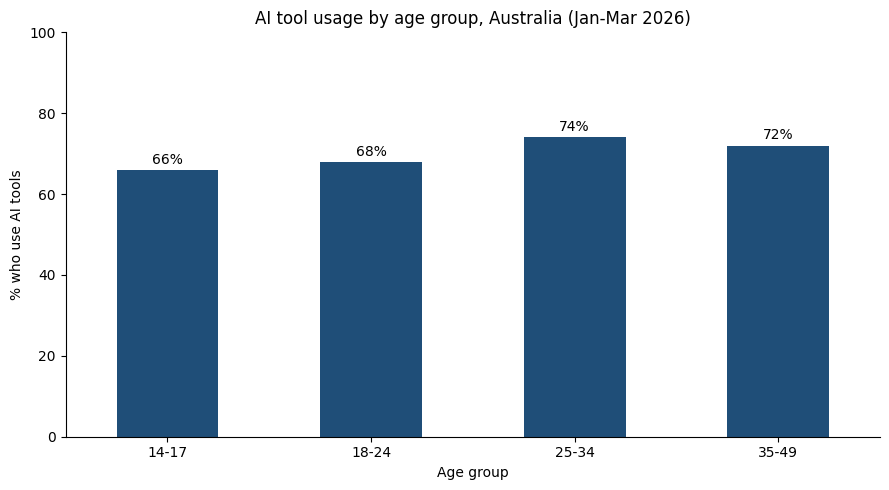

Highest usage: 25-34 (74%)


In [6]:
metric_au = "Use AI tools (ChatGPT, Copilot, Gemini, etc.)"
au = data[(data["country"] == "Australia") & (data["metric"] == metric_au)]

age_order = ["14-17", "18-24", "25-34", "35-49", "50-64", "65+"]
au = au.set_index("age_group").loc[[a for a in age_order if a in au["age_group"].values]]

ax = au["value"].plot(kind="bar", color="#1F4E78", rot=0)
ax.set_title("AI tool usage by age group, Australia (Jan-Mar 2026)")
ax.set_xlabel("Age group")
ax.set_ylabel("% who use AI tools")
ax.set_ylim(0, 100)
for i, v in enumerate(au["value"]):
    ax.text(i, v + 1.5, f"{v:.0f}%", ha="center")
plt.tight_layout()
plt.show()

peak = au["value"].idxmax()
print(f"Highest usage: {peak} ({au['value'].max():.0f}%)")

## 5. Compare all metrics that have 2 or more age groups

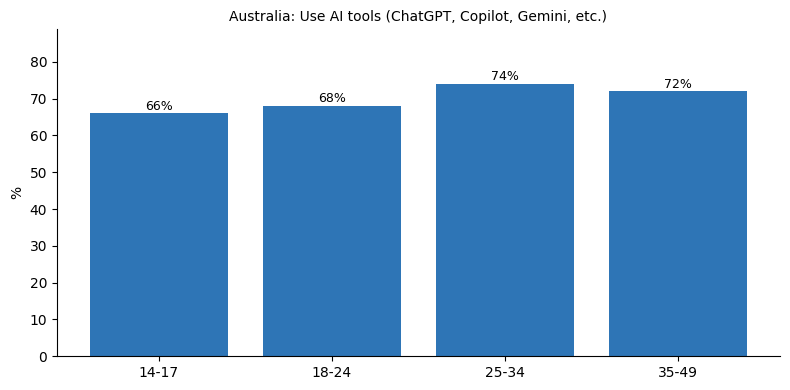

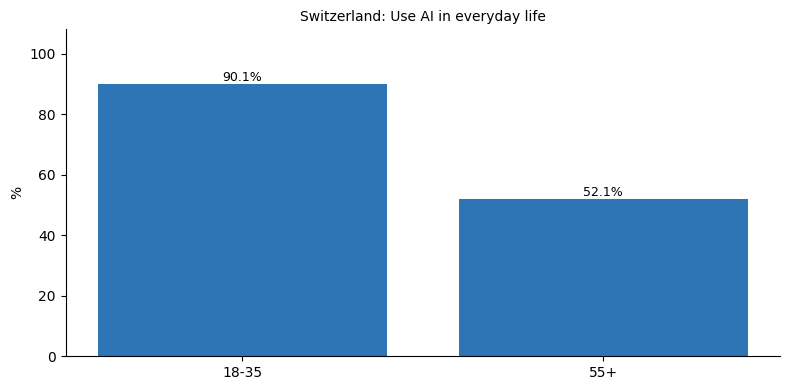

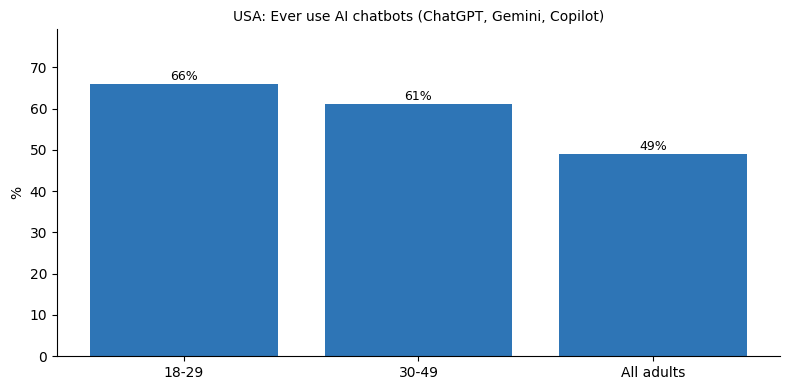

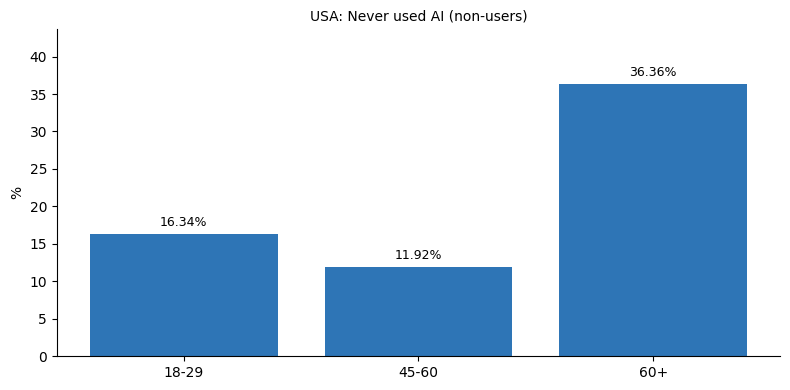

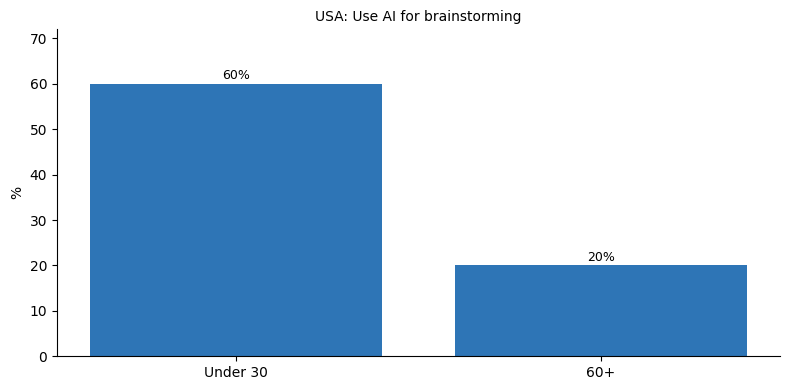

In [7]:
metric_counts = data.groupby(["country", "metric"]).size()
multi = metric_counts[metric_counts >= 2].reset_index()[["country", "metric"]]

for _, row in multi.iterrows():
    sub = data[(data["country"] == row["country"]) & (data["metric"] == row["metric"])]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(sub["age_group"], sub["value"], color="#2E75B6")
    ax.set_title(f"{row['country']}: {row['metric']}", fontsize=10)
    ax.set_ylabel("%")
    for i, v in enumerate(sub["value"]):
        ax.text(i, v + 1, f"{v:g}%", ha="center", fontsize=9)
    ax.set_ylim(0, max(sub["value"]) * 1.2)
    plt.tight_layout()
    plt.show()

## 6. The younger vs older gap
We compare a younger group with an older group **only within the same source and metric**, so the comparison is fair.
The gap is measured in percentage points (pp).

In [8]:
pairs = [
    # (country, source, metric, younger group, older group)
    ("Switzerland", "Swissinfo", "Use AI in everyday life", "18-35", "55+"),
    ("USA", "Implicator.ai", "Use AI for brainstorming", "Under 30", "60+"),
    ("USA", "Exploding Topics", "Never used AI (non-users)", "18-29", "60+"),
]

rows = []
for country, source, metric, young, old in pairs:
    sub = data[(data["country"] == country) & (data["source"] == source) & (data["metric"] == metric)]
    y = sub.loc[sub["age_group"] == young, "value"].iloc[0]
    o = sub.loc[sub["age_group"] == old, "value"].iloc[0]
    rows.append({"country": country, "source": source, "metric": metric,
                 "younger": young, "younger_%": y,
                 "older": old, "older_%": o,
                 "gap_pp": round(y - o, 1)})

gap = pd.DataFrame(rows)
gap

,country,source,metric,younger,younger_%,older,older_%,gap_pp
0,Switzerland,Swissinfo,Use AI in everyday life,18-35,90.10,55+,52.10,38.0
1,USA,Implicator.ai,Use AI for brainstorming,Under 30,60.00,60+,20.00,40.0
2,USA,Exploding Topics,Never used AI (non-users),18-29,16.34,60+,36.36,-20.0


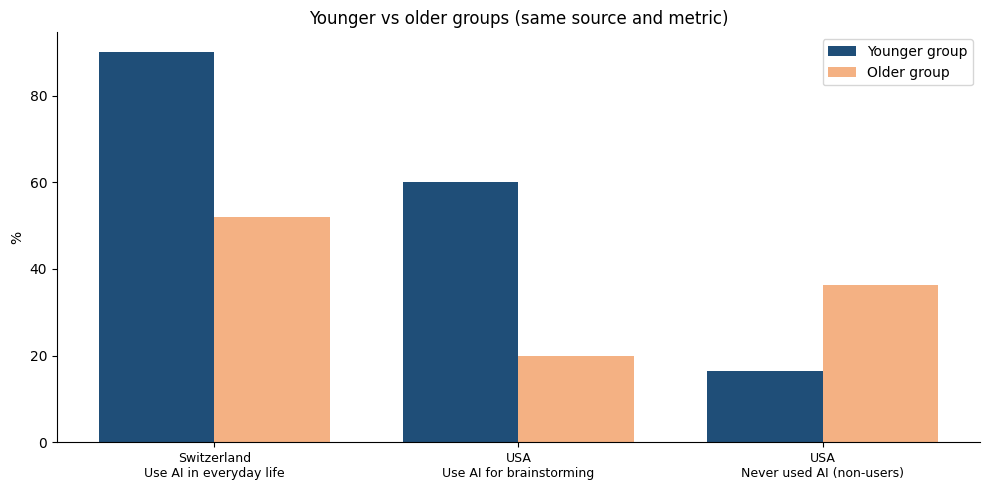

In [9]:
labels = [f"{r.country}\n{r.metric[:28]}" for r in gap.itertuples()]
x = np.arange(len(gap))
w = 0.38

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w/2, gap["younger_%"], w, label="Younger group", color="#1F4E78")
ax.bar(x + w/2, gap["older_%"], w, label="Older group", color="#F4B183")
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("%")
ax.set_title("Younger vs older groups (same source and metric)")
ax.legend()
plt.tight_layout()
plt.show()

**Note:** in the non-users row, *higher* means *less* AI use, so the sign of the gap is reversed there.
The Swiss and brainstorming rows are the cleanest like-for-like comparisons.

## 7. Non-users by age group (US, Exploding Topics)

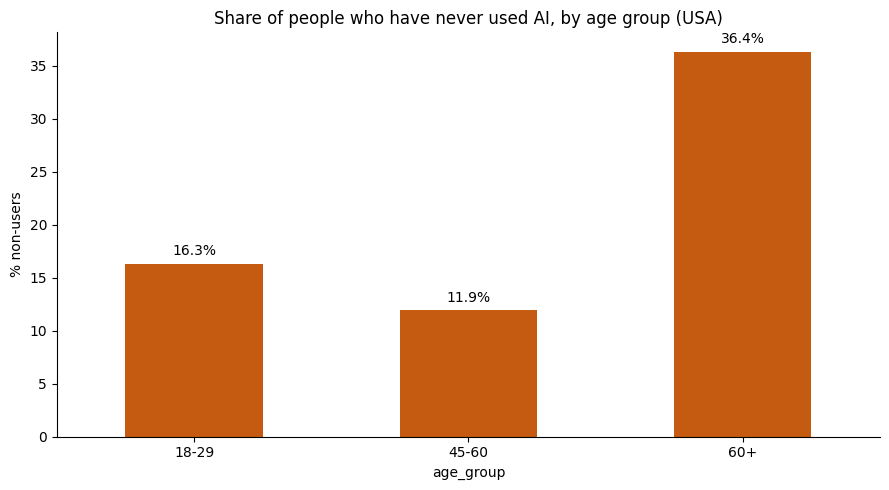

In [10]:
nu = data[(data["metric"] == "Never used AI (non-users)")].copy()
order = ["18-29", "45-60", "60+"]
nu = nu.set_index("age_group").loc[order]

ax = nu["value"].plot(kind="bar", color="#C55A11", rot=0)
ax.set_title("Share of people who have never used AI, by age group (USA)")
ax.set_ylabel("% non-users")
for i, v in enumerate(nu["value"]):
    ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()